In [ ]:
import numpy as np
import xtrack as xt
import xpart as xp
import matplotlib.pyplot as plt
from class_geometry.ring_geometry.ring_geometry import RingGeometry
from TrackingRCS import TrackingRCS, off_dE, plot_emit_2rcs
from matplotlib.ticker import NullLocator, FixedLocator, FixedFormatter

In [ ]:
plt.rc('axes', labelsize=14)     # fontsize of the x and y labels
plt.rc('xtick', labelsize=14)    # fontsize of the tick labels
plt.rc('ytick', labelsize=14)    # fontsize of the tick labels
plt.rc('legend', fontsize=14)    # legend fontsize

In [12]:
n_part = 5000
n_turn_rcs = 17
t_acc = 0.34 * 1e-3
nemitt_x = 25e-6
nemitt_y = 25e-6

In [ ]:
input_rcs = {
    '8arc_noramp_nomEl' : {
        'file_input' : '/mnt/c/muco/code/lattices/lattice_08_25/line_RCS1_gf_normal_qp_8_arc_v2.json',
        'file_geo' : '/mnt/c/muco/code//lattices/lattice_08_25/para_RCS1_gf_normal_qp__8_arc.json',
        'sz' : 30.2e-12,
        'ramp' : False,
        'label' : r'8a, No ramp, $\epsilon_s$',
    },
    '8arc_noramp_low_el' : {
        'file_input' : '/mnt/c/muco/code/lattices/lattice_08_25/line_RCS1_gf_normal_qp_8_arc_v2.json',
        'file_geo' : '/mnt/c/muco/code/lattices/lattice_08_25/para_RCS1_gf_normal_qp__8_arc.json',
        'sz' : 30.2e-12/3,
        'ramp' : False,
        'label' : r'8a, No ramp, $\epsilon_s$/10',
    },
    '8arc_ramp_low_el' : {
        'file_input' : '/mnt/c/muco/code/lattices/lattice_08_25/line_RCS1_gf_normal_qp_8_arc_v2.json',
        'file_geo' : '/mnt/c/muco/code/lattices/lattice_08_25/para_RCS1_gf_normal_qp__8_arc.json',
        'sz' : 30.2e-12/3,
        'ramp' : True,
        'label' : r'8a, Ramp, $\epsilon_s$/10',
    },
    '28arc_noramp_nomEl' : {
        'file_input' : '/mnt/c/muco/code/lattices/lattice_08_25/line_RCS1_gf_normal_qp_28_arc.json',
        'file_geo' : '/mnt/c/muco/code/lattices/lattice_08_25/para_RCS1_gf_normal_qp__28_arc.json',
        'sz' : 30.2e-12,
        'ramp' : False,
        'label' : r'28a, No ramp, $\epsilon_s$',
    },
    '28arc_ramp_nomEl' : {
        'file_input' : '/mnt/c/muco/code/lattices/lattice_08_25/line_RCS1_gf_normal_qp_28_arc.json',
        'file_geo' : '/mnt/c/muco/code/lattices/lattice_08_25/para_RCS1_gf_normal_qp__28_arc.json',
        'sz' : 30.2e-12,
        'ramp' : True,
        'label' : r'28a, Ramp, $\epsilon_s$',
    },
    '32arc_noramp_nomEl' : {
        'file_input' : '/mnt/c/muco/code/lattices/lattices_final_report/RCS1_gf/line_RCS1_gf_normal_qp_32_arc.json',
        'file_geo' : '/mnt/c/muco/code/lattices/lattices_final_report/RCS1_gf/para_RCS1_gf_normal_qp__32_arc.json',
        'sz' : 30.2e-12,
        'ramp' : False,
        'label' : r'32a, No ramp, $\epsilon_s$',
    },
    '32arc_ramp_nomEl' : {
        'file_input' : '/mnt/c/muco/code/lattices/lattices_final_report/RCS1_gf/line_RCS1_gf_normal_qp_32_arc.json',
        'file_geo' : '/mnt/c/muco/code/lattices/lattices_final_report/RCS1_gf/para_RCS1_gf_normal_qp__32_arc.json',
        'sz' : 30.2e-12,
        'ramp' : True,
        'label' : r'32a, Ramp, $\epsilon_s$',
    },
}

Loading line from dict: 100%|██████████| 43/43 [00:00<00:00, 14096.85it/s]


Done loading line from dict.           
[np.float64(0.030099773343003455), np.float64(0.02657223002722975), np.float64(0.024048304631651918), np.float64(0.02212831624012518), np.float64(0.020604663187526073), np.float64(0.01935754054736788), np.float64(0.018312350625417195), np.float64(0.017419926795561314), np.float64(0.01664635020915184), np.float64(0.015967406684562813), np.float64(0.01536527902585011), np.float64(0.014826475295327546), np.float64(0.014340627930940486), np.float64(0.01389959629837384), np.float64(0.01349690411123844)]


Loading line from dict: 100%|██████████| 159/159 [00:00<00:00, 14222.53it/s]

Done loading line from dict.           


[np.float64(0.13351982372520765), np.float64(0.11709304248108854), np.float64(0.1055359565298914), np.float64(0.0968383264851615), np.float64(0.08998746850225492), np.float64(0.08441084832046347), np.float64(0.07975674588375536), np.float64(0.07579614260985645), np.float64(0.0723724475733224), np.float64(0.0693741612769454), np.float64(0.06672012672952449), np.float64(0.06434910935958416), np.float64(0.06221400389053339), np.float64(0.060278289904603155), np.float64(0.05851266771356689)]


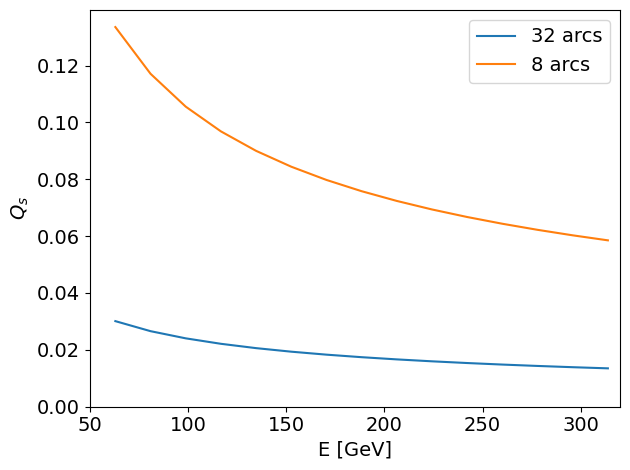

In [ ]:
rcs_name = '32arc_ramp_nomEl'
file_input = input_rcs[rcs_name]['file_input']
file_geo = input_rcs[rcs_name]['file_geo']
line = xt.Line.from_json(file_input)
rcs = RingGeometry(file_geo)
off_dE(line)
energies = np.linspace(rcs.injection_energy, rcs.extraction_energy, 15)
qs = []
qx = []
qy = []
for e_beam in energies:
    line.particle_ref = xp.Particles(
        p0c=e_beam,
        q0=1, 
        mass0=xp.MUON_MASS_EV
        )
    tw = line.twiss()
    qs.append(tw.qs)
    qx.append(tw.qx)
    qy.append(tw.qy)

fig_qs = plt.figure(figsize=(6.4,4.8))
plt.plot(energies * 1e-9, qs, label='32 arcs')
print(qs)

rcs_name = '8arc_noramp_nomEl'
file_input = input_rcs[rcs_name]['file_input']
file_geo = input_rcs[rcs_name]['file_geo']
line = xt.Line.from_json(file_input)
rcs = RingGeometry(file_geo)
off_dE(line)
energies = np.linspace(rcs.injection_energy, rcs.extraction_energy, 15)
qs = []
for e_beam in energies:
    line.particle_ref = xp.Particles(
        p0c=e_beam,
        q0=1, 
        mass0=xp.MUON_MASS_EV
        )
    tw = line.twiss()
    qs.append(tw.qs)
print(qs)

plt.plot(energies * 1e-9, qs, label='8 arcs')
plt.xlabel('E [GeV]')
plt.ylabel(r'$Q_s$')
plt.xlim(50, 320)
plt.ylim(0)
plt.legend()
plt.tight_layout()
plt.show()



In [ ]:
key_rcs = '32arc_ramp_nomEl'
file_input = input_rcs[key_rcs]['file_input']
file_geo = input_rcs[key_rcs]['file_geo']
line_arc = xt.Line.from_json(file_input)
rcs = RingGeometry(file_geo)
ramp = input_rcs[key_rcs]['ramp']
sigma_z = input_rcs[key_rcs]['sz']

n_sigma = 5
method = 'var_ref'
RF_tuning = False
adapt_part = False
adapt_per = 95
plt_twiss = False
plt_sepa = True


Loading line from dict:   0%|          | 0/159 [00:00<?, ?it/s]

Loading line from dict: 100%|██████████| 159/159 [00:00<00:00, 13783.93it/s]

Done loading line from dict.           


----- Generating particle distribution -----
*** Maximum RMS bunch length 0.03634698528852931m.


RFBucketMatcher: failed to converge with Brent method, continuing with Newton-Raphson method.


... distance to target bunch length: 4.5806e-04
... distance to target bunch length: 2.6289e-02
... distance to target bunch length: 1.4665e-04
... distance to target bunch length: 2.5275e-04
... distance to target bunch length: 2.1001e-07
--> Bunch length: 0.009053732530532673
--> Emittance: 0.2716233590240607
Emittance x at injection, before 2nd order matching 2.527944609359703e-05
Emittance s at injection 0.025176132725602693
----- Initial particle distribution and separatrix -----


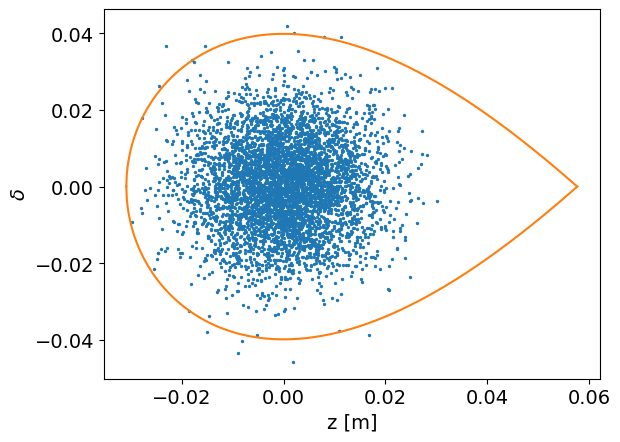

----- Build RCS line -----
----- Insert particle monitors and apertures -----
Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
----- Tracking results at injection -----
ex = 2.5303899459575707e-05
ey = 2.544568853065687e-05
es = 0.024865024468770376
----- Tracking results at extraction -----
ex = 0.00018314461178106978
ey = 2.6208790074951677e-05
es = 0.025893306814272796
tr = 0.9976
----- Growth at extraction -----
ex = 623.7801907712003
ey = 2.998942407769488
es = 4.1354568011541994


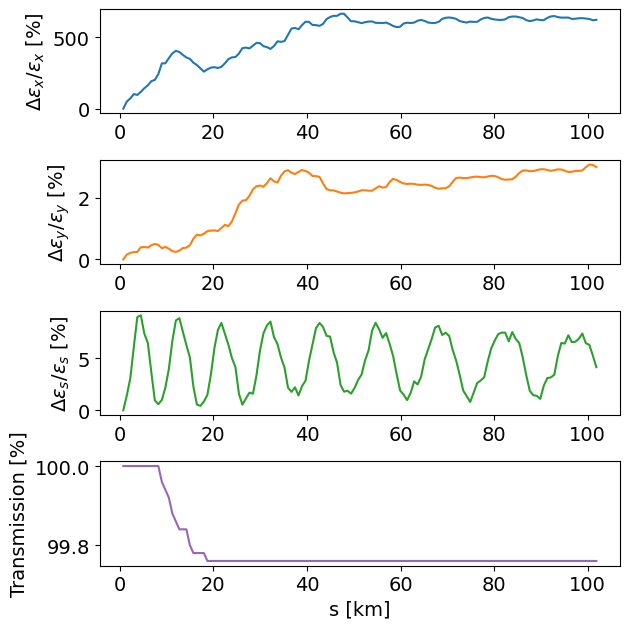

In [19]:
track_rcs = TrackingRCS(
        line = line_arc,
        rcs =rcs,
        n_turn_rcs = n_turn_rcs,
        n_part=n_part,
        nemitt_x=nemitt_x,
        nemitt_y=nemitt_y,
        sigma_z=sigma_z,
        t_acc = t_acc,
        ramp = ramp,
        n_sigma = n_sigma,
        method = method,
        RF_tuning = RF_tuning,
        adapt_part = adapt_part,
        adapt_percentile = adapt_per,
        plt_twiss = plt_twiss,
        plt_sepa = plt_sepa,
    )

In [ ]:
folder = '/mnt/c/muco/Results/figures/chap6/tracking_v2/RCS1_'
adapt_name = 'ad2nd' if adapt_part else 'noad2nd'
save_fig = False
if save_fig:
    track_rcs.fig_tracking.savefig(folder+f'{key_rcs}_{adapt_name}')

Loading line from dict: 100%|██████████| 159/159 [00:00<00:00, 13525.62it/s]

Done loading line from dict.           
----- Generating particle distribution -----
*** Maximum RMS bunch length 0.03634698528852932m.


/home/ls276867/.venvs/xsuite/lib/python3.11/site-packages/scipy/integrate/_quadpack_py.py:1264: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  quad_r = quad(f, low, high, args=args, full_output=self.full_output,
RFBucketMatcher: failed to converge with Brent method, continuing with Newton-Raphson method.


... distance to target bunch length: 4.5806e-04
... distance to target bunch length: 2.6289e-02
... distance to target bunch length: 1.4665e-04
... distance to target bunch length: 2.5275e-04
... distance to target bunch length: 2.1001e-07
--> Bunch length: 0.009053732530532672
--> Emittance: 0.2695584752465458
Emittance x at injection, before 2nd order matching 2.4737415766026835e-05
Emittance s at injection 0.02487305635048219
Matched distribution adapted to second order with max delta: 0.00613811617474533
----- Initial particle distribution and separatrix -----


/mnt/c/muco/code/TrackingRCS.py:312: RuntimeWarning: invalid value encountered in sqrt
  Ax = np.sqrt(tw_loc[:, 0] / self.tw_arc.betx[0])
/mnt/c/muco/code/TrackingRCS.py:313: RuntimeWarning: invalid value encountered in sqrt
  Bx = (self.tw_arc.alfx[0] - tw_loc[:,1]) / np.sqrt(self.tw_arc.betx[0] * tw_loc[:,0])


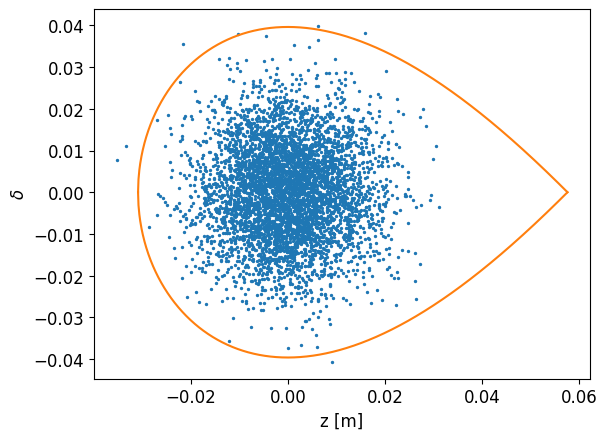

----- Build RCS line -----
----- Insert particle monitors and apertures -----
Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
----- Tracking results at injection -----
ex = 2.8915936976017407e-05
ey = 2.5241212991510497e-05
es = 0.02237421462283842
----- Tracking results at extraction -----
ex = 0.00015532056511669305
ey = 2.4871843456020637e-05
es = 0.0213365090604568
tr = 0.9696
----- Growth at extraction -----
ex = 437.14519175192004
ey = -1.4633588948918286
es = -4.637953018124645


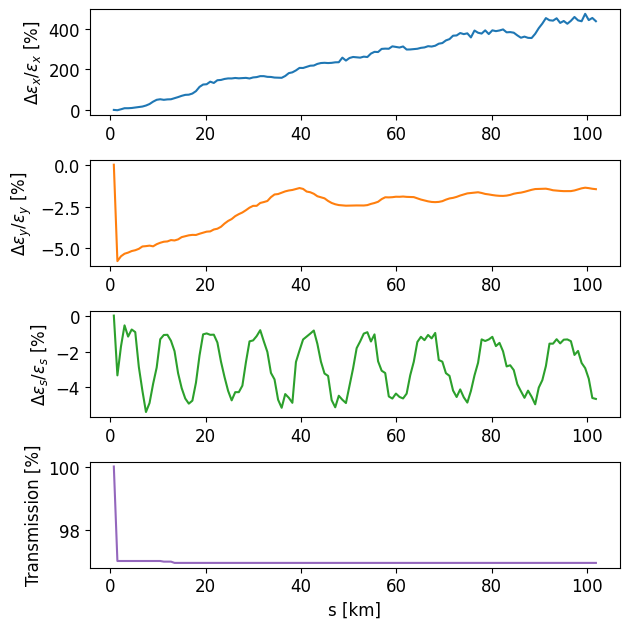

----- Generating particle distribution -----
*** Maximum RMS bunch length 0.03634698528852932m.


RFBucketMatcher: failed to converge with Brent method, continuing with Newton-Raphson method.


... distance to target bunch length: 4.5806e-04
... distance to target bunch length: 2.6289e-02
... distance to target bunch length: 1.4665e-04
... distance to target bunch length: 2.5275e-04
... distance to target bunch length: 2.1001e-07
--> Bunch length: 0.009053732530532672
--> Emittance: 0.2695584752465458
Emittance x at injection, before 2nd order matching 2.5257127006446557e-05
Emittance s at injection 0.02511697174748584
----- Initial particle distribution and separatrix -----


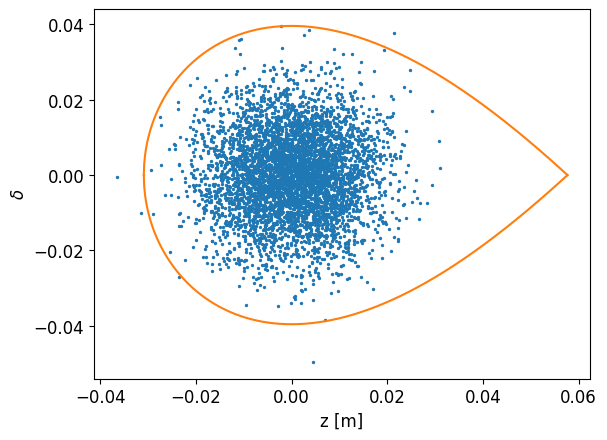

----- Build RCS line -----
----- Insert particle monitors and apertures -----
Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
----- Tracking results at injection -----
ex = 2.524781883381736e-05
ey = 2.5449667804928946e-05
es = 0.025062349329349642
----- Tracking results at extraction -----
ex = 0.0001945864052382877
ey = 2.657216594233392e-05
es = 0.025417004894788892
tr = 0.9992
----- Growth at extraction -----
ex = 670.7058044065784
ey = 4.410659290364386
es = 1.4150930576325704


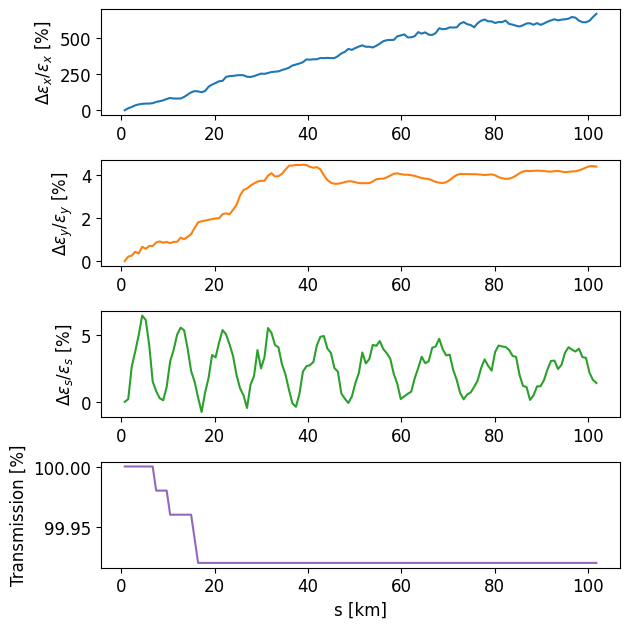

Loading line from dict: 100%|██████████| 43/43 [00:00<00:00, 10961.84it/s]


Done loading line from dict.           
----- Generating particle distribution -----
*** Maximum RMS bunch length 0.03634698502024826m.


RFBucketMatcher: failed to converge with Brent method, continuing with Newton-Raphson method.


... distance to target bunch length: 4.8345e-04
... distance to target bunch length: 2.6289e-02
... distance to target bunch length: 1.4665e-04
... distance to target bunch length: 2.5275e-04
... distance to target bunch length: 2.1001e-07
--> Bunch length: 0.009053732530532679
--> Emittance: 0.3168478051307226
Emittance x at injection, before 2nd order matching 2.50062328627447e-05
Emittance s at injection 0.029556684116812705
Matched distribution adapted to second order with max delta: 0.02135713945405009
----- Initial particle distribution and separatrix -----


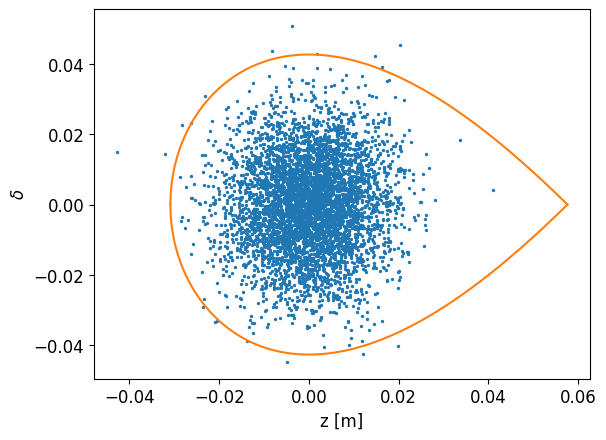

----- Build RCS line -----
----- Insert particle monitors and apertures -----
Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
----- Tracking results at injection -----
ex = 2.7266884442777516e-05
ey = 2.4701620205458398e-05
es = 0.02924073179564053
----- Tracking results at extraction -----
ex = 2.5031593749079665e-05
ey = 2.4609434838961253e-05
es = 0.02985716346447853
tr = 0.998
----- Growth at extraction -----
ex = -8.197822154521717
ey = -0.37319562737335615
es = 2.1081266814598076


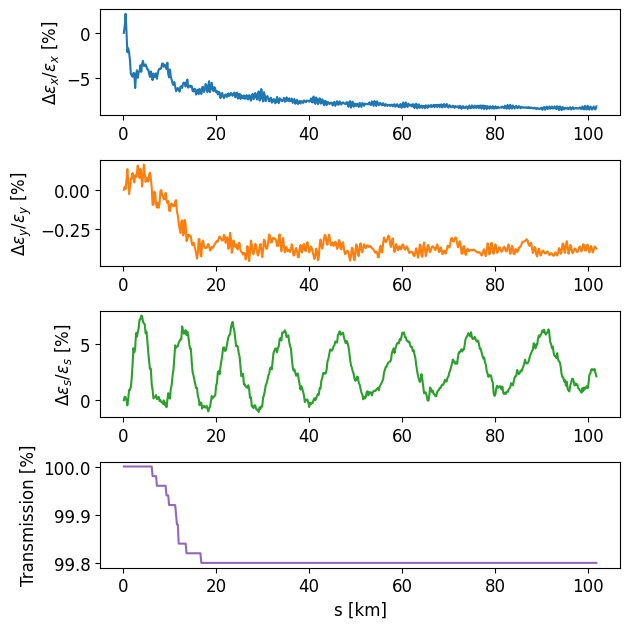

----- Generating particle distribution -----
*** Maximum RMS bunch length 0.03634698502024826m.


RFBucketMatcher: failed to converge with Brent method, continuing with Newton-Raphson method.


... distance to target bunch length: 4.8345e-04
... distance to target bunch length: 2.6289e-02
... distance to target bunch length: 1.4665e-04
... distance to target bunch length: 2.5275e-04
... distance to target bunch length: 2.1001e-07
--> Bunch length: 0.009053732530532679
--> Emittance: 0.3168478051307226
Emittance x at injection, before 2nd order matching 2.5622286759344016e-05
Emittance s at injection 0.02865563782164932
----- Initial particle distribution and separatrix -----


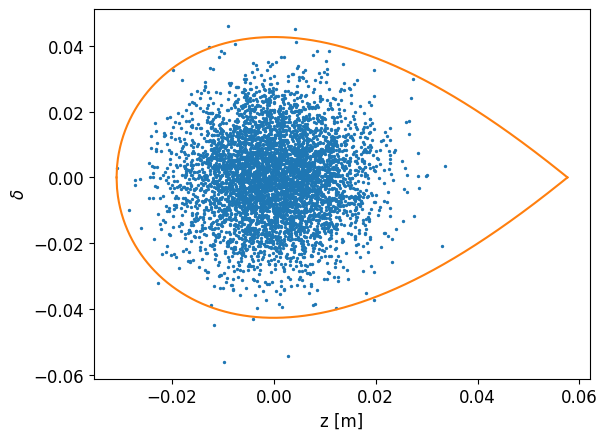

----- Build RCS line -----
----- Insert particle monitors and apertures -----
Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
----- Tracking results at injection -----
ex = 2.5619838898187424e-05
ey = 2.5364621971315186e-05
es = 0.028464804963753042
----- Tracking results at extraction -----
ex = 3.025541044151479e-05
ey = 2.533258161277779e-05
es = 0.02915970738622535
tr = 0.999
----- Growth at extraction -----
ex = 18.09367951823978
ey = -0.12631908558949154
es = 2.4412688699507816


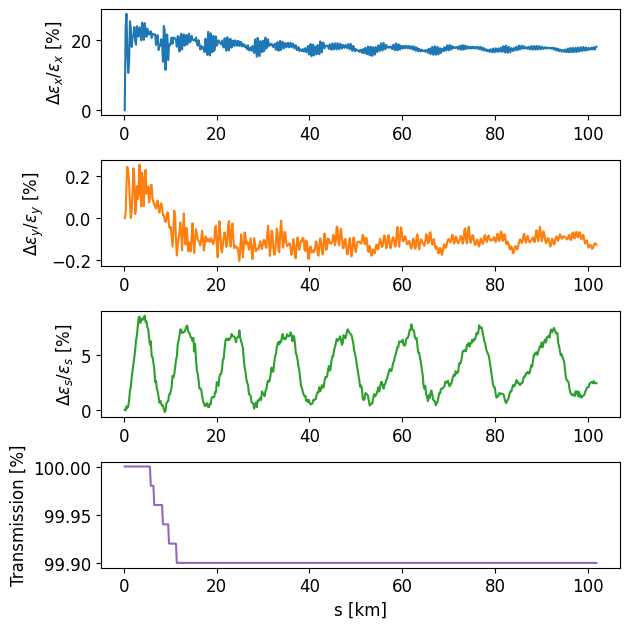

In [7]:
keys = ['8arc_noramp_nomEl', '32arc_noramp_nomEl']
adapt = [70, 95]
n_sigma = 5
method = 'var_ref'
RF_tuning = False
plt_twiss = False
plt_sepa = True
ramp = False

res = {}
for key_rcs, adapt_per in zip(keys, adapt):
    file_input = input_rcs[key_rcs]['file_input']
    file_geo = input_rcs[key_rcs]['file_geo']

    line_arc = xt.Line.from_json(file_input)
    rcs = RingGeometry(file_geo)

    ramp = input_rcs[key_rcs]['ramp']
    sigma_z = input_rcs[key_rcs]['sz']

    tr_adapt = TrackingRCS(
        line = line_arc,
        rcs =rcs,
        n_turn_rcs = n_turn_rcs,
        n_part=n_part,
        nemitt_x=nemitt_x,
        nemitt_y=nemitt_y,
        sigma_z=sigma_z,
        t_acc = t_acc,
        ramp = ramp,
        n_sigma = n_sigma,
        method = method,
        RF_tuning = RF_tuning,
        adapt_part = True,
        adapt_percentile = adapt_per,
        plt_twiss = plt_twiss,
        plt_sepa = plt_sepa,
    )

    tr_no_adapt = TrackingRCS(
        line = line_arc,
        rcs =rcs,
        n_turn_rcs = n_turn_rcs,
        n_part=n_part,
        nemitt_x=nemitt_x,
        nemitt_y=nemitt_y,
        sigma_z=sigma_z,
        t_acc = t_acc,
        ramp = ramp,
        n_sigma = n_sigma,
        method = method,
        RF_tuning = RF_tuning,
        adapt_part = False,
        adapt_percentile = adapt_per,
        plt_twiss = plt_twiss,
        plt_sepa = plt_sepa,
    )

    res[key_rcs] = {}
    res[key_rcs]['adapt'] = tr_adapt
    res[key_rcs]['no_adapt'] = tr_no_adapt


In [ ]:
def plot_emit_rcs(results, labels, colors=None, legend_title=None,
                  yticks_x=(-10, 0, 20, 100, 500), linthresh=10):
    """
    Compare les évolutions des émittances et de la transmission
    pour un nombre quelconque de configurations de RCS.

    Parameters
    ----------
    results : list of dict
        Dictionnaires de résultats (clés : "s", "emitx", "emity",
        "emits", "transmission").
    labels : list of str
        Labels de la légende (même ordre que `results`).
    colors : list, optional
        Couleurs des courbes. Par défaut : cycle tab10.
    legend_title : str, optional
        Titre de la légende.
    yticks_x : sequence of float
        Ticks affichés sur l'axe y de l'émittance horizontale (échelle symlog).
    linthresh : float
        Seuil (en %) en dessous duquel l'échelle symlog est linéaire.
    """
    n = len(results)

    if colors is None:
        colors = [f"tab:{c}" for c in
                  ["blue", "orange", "green", "red", "purple",
                   "brown", "pink", "gray"]][:n]

    fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(6.4, 6.4), sharex=True)

    for res, lab, cl in zip(results, labels, colors):
        s = res["s"] * 1e-3
        ex, ey, es, tr = res["emitx"], res["emity"], res["emits"], res["transmission"]

        axes[0].plot(s, (ex - ex[0]) / ex[0] * 100, color=cl, label=lab)
        axes[1].plot(s, (ey - ey[0]) / ey[0] * 100, color=cl)
        axes[2].plot(s, (es - es[0]) / es[0] * 100, color=cl)
        axes[3].plot(s, tr * 100, color=cl)

    # Échelle symlog (0 impossible en log pur) avec ticks imposés, ylim automatique
    ax = axes[0]
    ax.set_yscale("symlog", linthresh=linthresh)
    ax.yaxis.set_major_locator(FixedLocator(yticks_x))
    ax.yaxis.set_major_formatter(FixedFormatter([f"{t:g}" for t in yticks_x]))
    ax.yaxis.set_minor_locator(NullLocator())

    axes[0].set_ylabel(r'$\Delta \epsilon_x / \epsilon_x$ [%]')
    axes[1].set_ylabel(r'$\Delta \epsilon_y / \epsilon_y$ [%]')
    axes[2].set_ylabel(r'$\Delta \epsilon_s / \epsilon_s$ [%]')
    axes[3].set_ylabel("Transmission [%]")
    axes[3].set_xlabel("s [km]")

    handles, leg_labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        leg_labels,
        loc="lower center",
        bbox_to_anchor=(0.57, -0.026),
        ncol=int(np.ceil(n / 2)),
        title=legend_title,
    )

    plt.tight_layout(rect=[0, 0.08 if legend_title else 0.06, 1, 1])
    plt.show()

    return fig

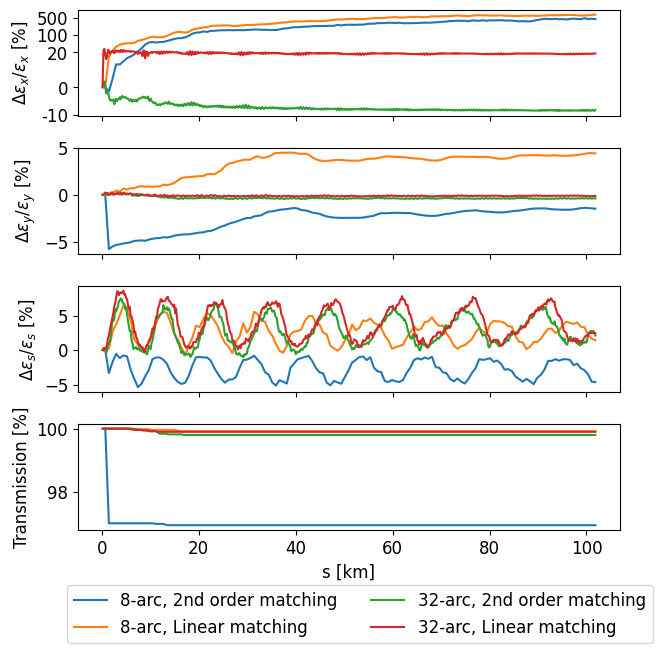

In [21]:
fig4 = plot_emit_rcs(
    results=[
        res['8arc_noramp_nomEl']['adapt'].track_res,
        res['8arc_noramp_nomEl']['no_adapt'].track_res,
        res['32arc_noramp_nomEl']['adapt'].track_res,
        res['32arc_noramp_nomEl']['no_adapt'].track_res,
    ],
    labels = [
        '8-arc, 2nd order matching',
        '8-arc, Linear matching',
        '32-arc, 2nd order matching',
        '32-arc, Linear matching',
        ],
)

In [28]:
folder = '/mnt/c/muco/Results/figures/chap6/tracking_v2/RCS1_'
save_fig = False
if save_fig:
    fig4.savefig(folder+'noramp_nomEl_matching_8_32', bbox_inches='tight')

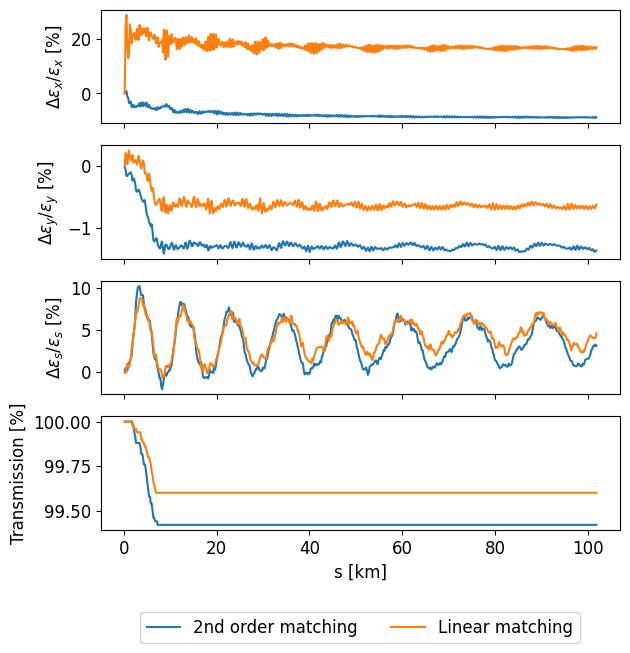

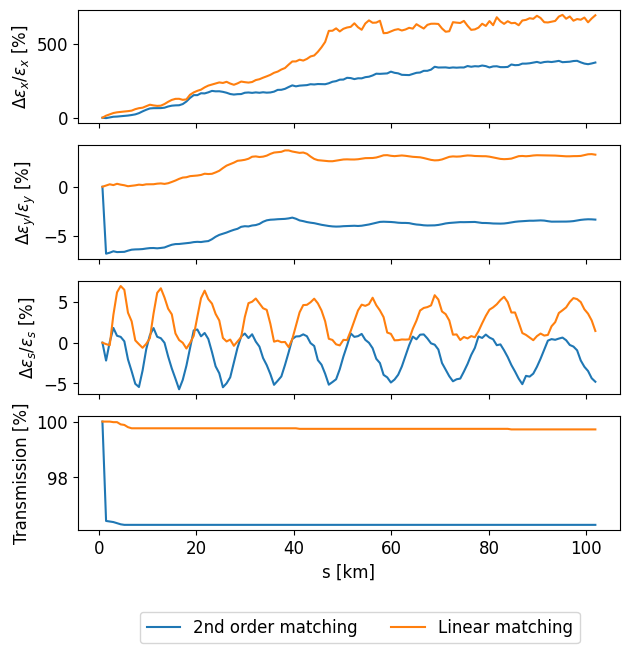

In [13]:
fig32 = plot_emit_2rcs(
    res['32arc_noramp_nomEl']['adapt'].track_res,  
    res['32arc_noramp_nomEl']['no_adapt'].track_res, 
    '2nd order matching', 
    'Linear matching')
fig8 = plot_emit_2rcs(
    res['8arc_noramp_nomEl']['adapt'].track_res,  
    res['8arc_noramp_nomEl']['no_adapt'].track_res, 
    '2nd order matching', 
    'Linear matching')

In [ ]:
folder = '/mnt/c/muco/Results/figures/chap6/tracking_v2/RCS1_'
save_fig = False
if save_fig:
    fig32.savefig(folder+'28arc_noramp_nomEl_matching', bbox_inches='tight')
    fig8.savefig(folder+'8arc_noramp_nomEl_matching', bbox_inches='tight')

Loading line from dict: 100%|██████████| 43/43 [00:00<00:00, 9021.81it/s]
/home/ls276867/.venvs/xsuite/lib/python3.11/site-packages/scipy/integrate/_quadpack_py.py:1264: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  quad_r = quad(f, low, high, args=args, full_output=self.full_output,


Done loading line from dict.           
----- Generating particle distribution -----
*** Maximum RMS bunch length 0.03634698502024826m.


RFBucketMatcher: failed to converge with Brent method, continuing with Newton-Raphson method.


... distance to target bunch length: 4.8345e-04
... distance to target bunch length: 2.6289e-02
... distance to target bunch length: 1.4665e-04
... distance to target bunch length: 2.5275e-04
... distance to target bunch length: 2.1001e-07
--> Bunch length: 0.009053732530532679
--> Emittance: 0.3168478051307226
Emittance at injection, before 2nd order matching 2.5161004808257716e-05
----- Initial particle distribution and separatrix -----


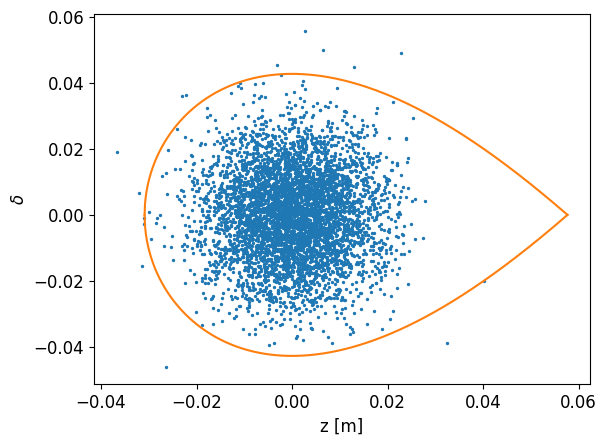

----- Build RCS line -----
----- Insert particle monitors and apertures -----


Slicing line: 100%|██████████| 23936/23936 [00:00<00:00, 261814.49it/s]


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
----- Tracking results at injection -----
ex = 2.5186894425078214e-05
ey = 2.465614686183251e-05
es = 0.0296139110211049
----- Tracking results at extraction -----
ex = 2.882136844172733e-05
ey = 2.4476973762240608e-05
es = 0.030224049713740955
tr = 0.9958
----- Growth at extraction -----
ex = 14.430020451550094
ey = -0.7266873473618819
es = 2.060311088937997


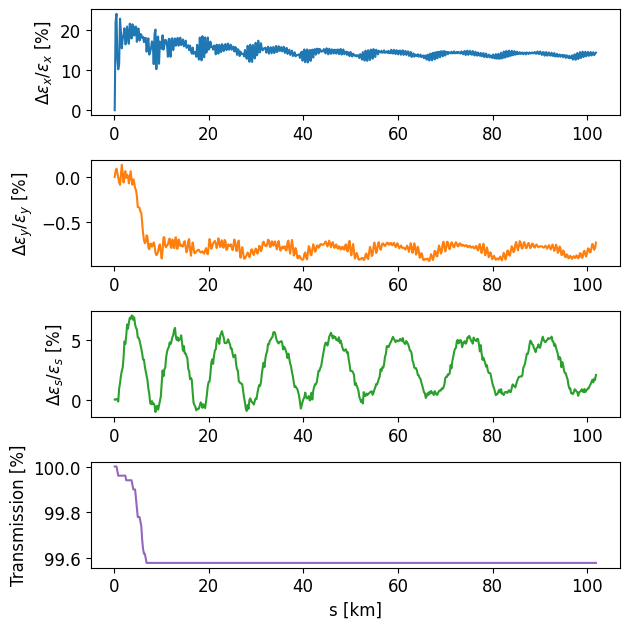

In [16]:
file_input = '/mnt/c/muco/code/lattices/lattices_final_report/RCS1_gf/line_RCS1_gf_normal_qp_32_arc.json'
file_geo = '/mnt/c/muco/code/lattices/lattices_final_report/RCS1_gf/para_RCS1_gf_normal_qp__32_arc.json'
ramp = False
line_arc = xt.Line.from_json(file_input)
rcs = RingGeometry(file_geo)
sigma_z = 30.2e-12

track = TrackingRCS(
    line = line_arc,
    rcs =rcs,
    n_turn_rcs = n_turn_rcs,
    n_part=n_part,
    nemitt_x=nemitt_x,
    nemitt_y=nemitt_y,
    sigma_z=sigma_z,
    t_acc = t_acc,
    ramp = ramp,
    n_sigma = n_sigma,
    method = method,
    RF_tuning = RF_tuning,
    plt_twiss = plt_twiss,
    plt_sepa = plt_sepa,
    adapt_part = False,
    adapt_percentile=95
)


Study for 32arc_noramp_nomEl


Loading line from dict: 100%|██████████| 43/43 [00:00<00:00, 1718.08it/s]

Done loading line from dict.           


----- Generating particle distribution -----
*** Maximum RMS bunch length 0.03634698502024826m.
... distance to target bunch length: 4.8345e-04
... distance to target bunch length: 2.6289e-02


RFBucketMatcher: failed to converge with Brent method, continuing with Newton-Raphson method.


... distance to target bunch length: 1.4665e-04
... distance to target bunch length: 2.5275e-04
... distance to target bunch length: 2.1001e-07
--> Bunch length: 0.009053732530532679
--> Emittance: 0.3168478051307226
Emittance x at injection, before 2nd order matching 2.5315304162711572e-05
Emittance s at injection 0.029368512763897313
Matched distribution adapted to second order with max delta: 0.021262280314142415
----- Initial particle distribution and separatrix -----


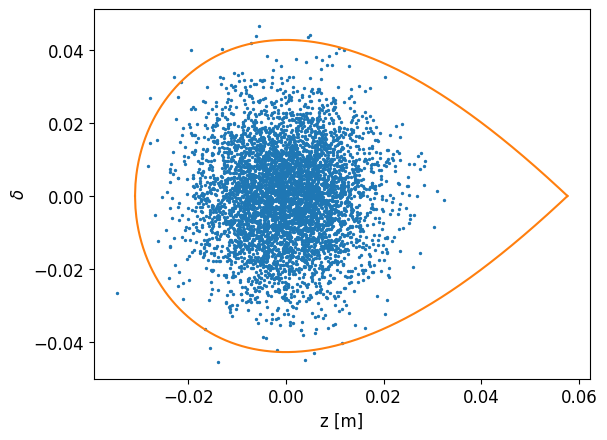

----- Build RCS line -----
----- Insert particle monitors and apertures -----


Slicing line: 100%|██████████| 23936/23936 [00:00<00:00, 34878.99it/s]


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
----- Tracking results at injection -----
ex = 2.75247078648821e-05
ey = 2.522495549452373e-05
es = 0.028711717836908218
----- Tracking results at extraction -----
ex = 2.5257165038472227e-05
ey = 2.500367425741592e-05
es = 0.02949971710481628
tr = 0.996
----- Growth at extraction -----
ex = -8.238208512661306
ey = -0.8772314272500907
es = 2.7445214960113162


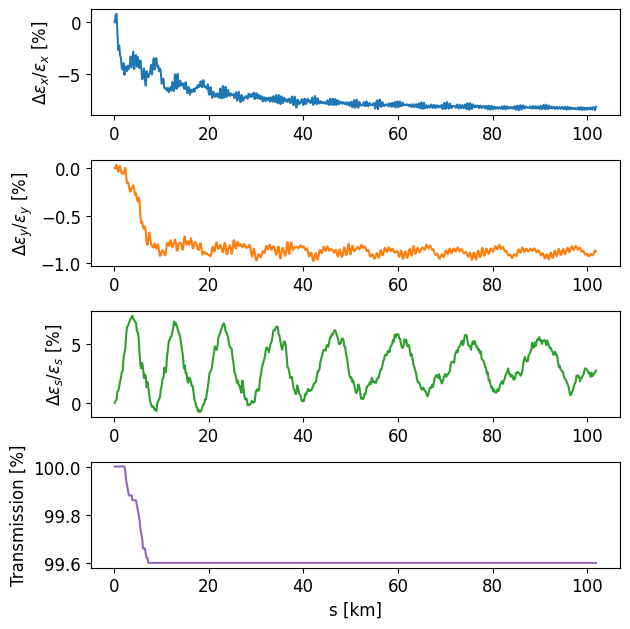

Study for 32arc_ramp_nomEl


Loading line from dict: 100%|██████████| 43/43 [00:00<00:00, 207.62it/s]


Done loading line from dict.           
----- Generating particle distribution -----
*** Maximum RMS bunch length 0.03634698502024826m.
... distance to target bunch length: 4.8345e-04


RFBucketMatcher: failed to converge with Brent method, continuing with Newton-Raphson method.


... distance to target bunch length: 2.6289e-02
... distance to target bunch length: 1.4665e-04
... distance to target bunch length: 2.5275e-04
... distance to target bunch length: 2.1001e-07
--> Bunch length: 0.009053732530532679
--> Emittance: 0.3168478051307226
Emittance x at injection, before 2nd order matching 2.486504312134976e-05
Emittance s at injection 0.02897948482608312
Matched distribution adapted to second order with max delta: 0.021842834540775964
----- Initial particle distribution and separatrix -----


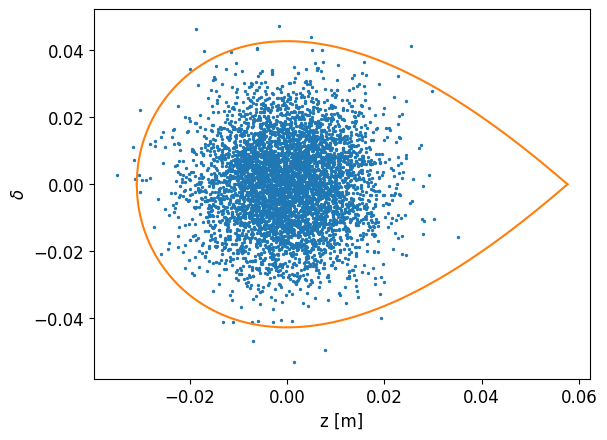

----- Build RCS line -----
----- Insert particle monitors and apertures -----


Slicing line: 100%|██████████| 34272/34272 [00:00<00:00, 64163.60it/s]


Compiling ContextCpu kernels...
Done compiling ContextCpu kernels.
----- Tracking results at injection -----
ex = 2.7333112095600652e-05
ey = 2.456558871092507e-05
es = 0.02869602133212932
----- Tracking results at extraction -----
ex = 2.821526683578289e-05
ey = 2.4335247884599972e-05
es = 0.029660859109891028
tr = 0.9956
----- Growth at extraction -----
ex = 3.227421513864951
ey = -0.9376564471367994
es = 3.362270213680927


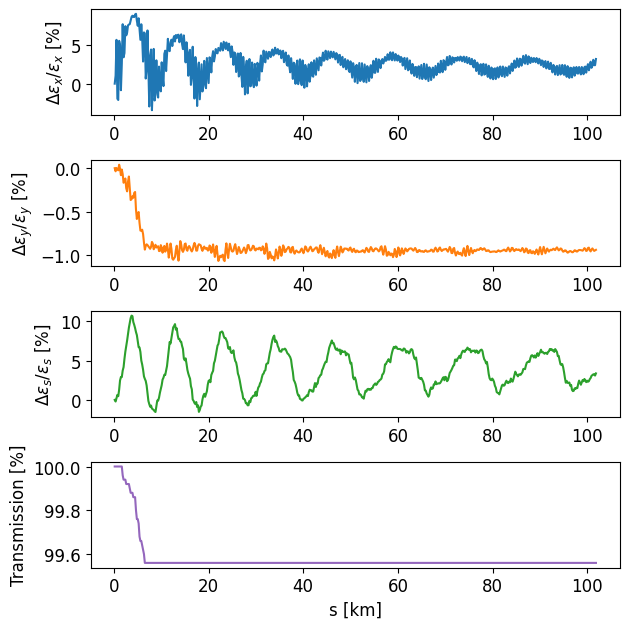

In [7]:
keys = [
    # '8arc_noramp_low_el', '8arc_ramp_low_el', 
    '32arc_noramp_nomEl', '32arc_ramp_nomEl'
    ]
adapt = [70, 95]
n_sigma = 5
method = 'var_ref'
RF_tuning = False
plt_twiss = False
plt_sepa = True

res = {}
for key_rcs in keys:
    print(f'Study for {key_rcs}')
    file_input = input_rcs[key_rcs]['file_input']
    file_geo = input_rcs[key_rcs]['file_geo']

    line_arc = xt.Line.from_json(file_input)
    rcs = RingGeometry(file_geo)

    ramp = input_rcs[key_rcs]['ramp']
    sigma_z = input_rcs[key_rcs]['sz']

    track = TrackingRCS(
        line = line_arc,
        rcs =rcs,
        n_turn_rcs = n_turn_rcs,
        n_part=n_part,
        nemitt_x=nemitt_x,
        nemitt_y=nemitt_y,
        sigma_z=sigma_z,
        t_acc = t_acc,
        ramp = ramp,
        n_sigma = n_sigma,
        method = method,
        RF_tuning = RF_tuning,
        plt_twiss = plt_twiss,
        plt_sepa = plt_sepa,
        adapt_part = True,
        adapt_percentile=95
    )

    res[key_rcs] = track


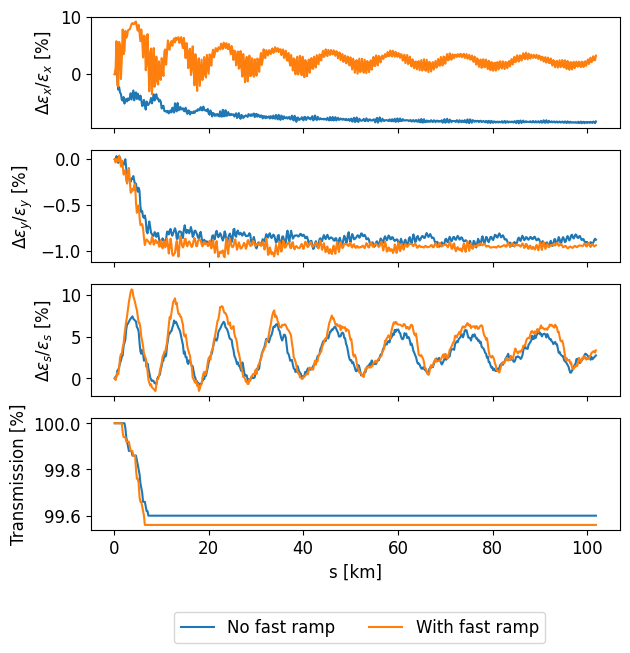

In [8]:
keys = ['8arc_noramp_low_el', '8arc_ramp_low_el', '28arc_noramp_nomEl', '28arc_ramp_nomEl']

fig32_ramp = plot_emit_2rcs(
    res['32arc_noramp_nomEl'].track_res,  
    res['32arc_ramp_nomEl'].track_res, 
    'No fast ramp', 
    'With fast ramp')
# fig8_ramp = plot_emit_2rcs(
#     res['8arc_noramp_low_el'].track_res,  
#     res['8arc_ramp_low_el'].track_res, 
#      'No fast ramp', 
#     'With fast ramp')